In [4]:
!pip install --upgrade "scikit-learn>=1.4" "xgboost>2.0" "optuna>3.0" "shap>=0.44"
!pip freeze > requirements.txt

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
import warnings
warnings.filterwarnings('ignore')

SEED = 45

# 1. Завантаження датасету
data = fetch_openml(name='anneal', version=1, as_frame=True, parser='auto')
X, y = data.data, data.target

# Приведення категоріальних ознак до типу object
cat_columns = X.select_dtypes(include=['category']).columns
X[cat_columns] = X[cat_columns].astype('object')

In [6]:
# 2. Визначення кількості спостережень, ознак та їх типів
print(f"Кількість спостережень: {X.shape[0]}")
print(f"Кількість ознак: {X.shape[1]}")
print("\nКількість ознак за типами:")
print(X.dtypes.value_counts())

Кількість спостережень: 898
Кількість ознак: 38

Кількість ознак за типами:
object     32
int64       4
float64     2
Name: count, dtype: int64


Топ-10 ознак за часткою пропусків:
marvi                           1.000000
s                               1.000000
p                               1.000000
corr                            1.000000
jurofm                          1.000000
m                               1.000000
bc                              0.998886
exptl                           0.997773
blue%2Fbright%2Fvarn%2Fclean    0.993318
phos                            0.992205
dtype: float64


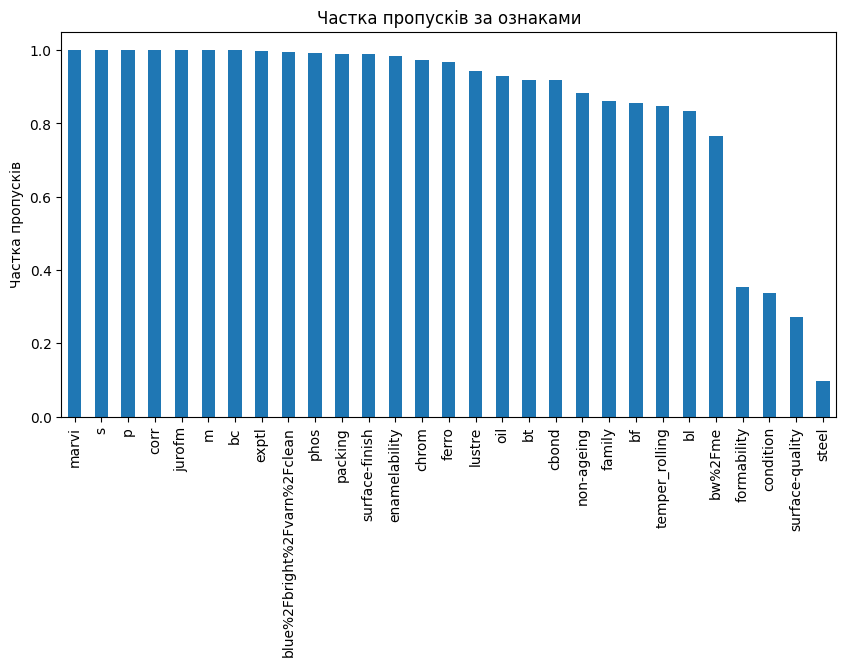


Видалено порожні ознаки: ['marvi', 's', 'p', 'corr', 'jurofm', 'm']
Видалено константні ознаки: ['product-type', 'temper_rolling', 'non-ageing', 'surface-finish', 'bc', 'bf', 'bt', 'bl', 'm', 'chrom', 'phos', 'cbond', 'marvi', 'exptl', 'ferro', 'corr', 'lustre', 'jurofm', 's', 'p']
Розмірність X після очищення: (898, 18)


In [7]:
# 3. Обчислення частки пропусків
missing_fractions = X.isna().mean().sort_values(ascending=False)
print("Топ-10 ознак за часткою пропусків:")
print(missing_fractions.head(10))

# Побудова графіка частки пропусків (вимога до звіту)
plt.figure(figsize=(10, 5))
missing_fractions[missing_fractions > 0].plot(kind='bar')
plt.title('Частка пропусків за ознаками')
plt.ylabel('Частка пропусків')
plt.show()

# Видалення порожніх (100% пропусків) та константних ознак
empty_cols = missing_fractions[missing_fractions == 1.0].index.tolist()
constant_cols = [col for col in X.columns if X[col].nunique(dropna=True) <= 1]

X = X.drop(columns=list(set(empty_cols + constant_cols)))
print(f"\nВидалено порожні ознаки: {empty_cols}")
print(f"Видалено константні ознаки: {constant_cols}")
print(f"Розмірність X після очищення: {X.shape}")

Початковий розподіл класів:
class
3    684
2     99
5     67
U     40
1      8
Name: count, dtype: int64


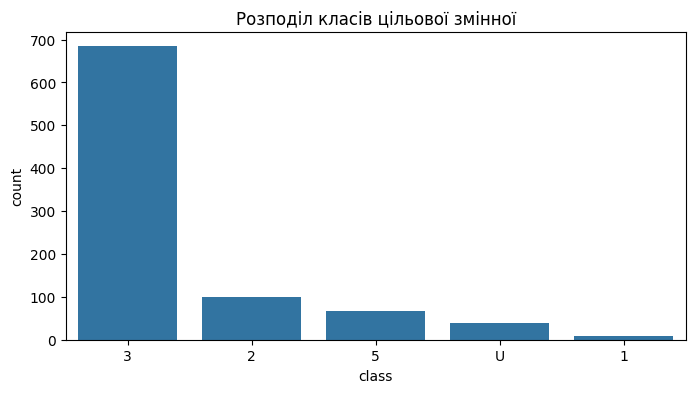


Залишено класи: ['3', '2', '5', 'U', '1']
Розмірність даних після виключення рідкісних класів: X=(898, 18), y=(898,)


In [8]:
# 4. Аналіз розподілу цільової змінної
class_counts = y.value_counts()
print("Початковий розподіл класів:")
print(class_counts)

# Побудова графіка розподілу (вимога до звіту)
plt.figure(figsize=(8, 4))
sns.countplot(x=y, order=class_counts.index)
plt.title('Розподіл класів цільової змінної')
plt.show()

# Виключення рідкісних класів (менше 5 спостережень)
min_samples = 5
valid_classes = class_counts[class_counts >= min_samples].index
mask = y.isin(valid_classes)

X, y = X[mask], y[mask]
print(f"\nЗалишено класи: {list(valid_classes)}")
print(f"Розмірність даних після виключення рідкісних класів: X={X.shape}, y={y.shape}")

In [9]:
from scipy.stats import chi2_contingency
from sklearn.preprocessing import LabelEncoder

# 5. Аналіз механізму пропусків
missing_rates_clean = X.isna().mean()
top_3_missing = missing_rates_clean[missing_rates_clean > 0].sort_values(ascending=False).head(3).index

print("Аналіз механізму пропусків (Chi-square test):")
for col in top_3_missing:
    # Бінарний індикатор: 1 - пропуск, 0 - не пропуск
    missing_indicator = X[col].isna().astype(int)

    # Таблиця спряженості "пропуск/не пропуск" х "клас"
    contingency_table = pd.crosstab(missing_indicator, y)

    # Критерій Хі-квадрат
    chi2, p, dof, expected = chi2_contingency(contingency_table)

    print(f"\nОзнака '{col}':")
    print(contingency_table)
    print(f"p-value: {p:.4e}")
    if p < 0.05:
         print("Висновок: Пропуски пов'язані з класом. Це скоріше MAR/MNAR, а не MCAR.")
    else:
         print("Висновок: Немає підстав відхиляти незалежність. Пропуски можуть бути MCAR.")

# 6. Кодування цільової змінної
le = LabelEncoder()
y_enc = le.fit_transform(y)
print(f"\nКласи до кодування: {le.classes_}")
print(f"Класи після кодування: {np.unique(y_enc)}")

Аналіз механізму пропусків (Chi-square test):

Ознака 'blue%2Fbright%2Fvarn%2Fclean':
class                         1   2    3   5   U
blue%2Fbright%2Fvarn%2Fclean                    
0                             1   4    1   0   0
1                             7  95  683  67  40
p-value: 1.5146e-07
Висновок: Пропуски пов'язані з класом. Це скоріше MAR/MNAR, а не MCAR.

Ознака 'packing':
class    1   2    3   5   U
packing                    
0        0   0    9   0   0
1        8  99  675  67  40
p-value: 5.8421e-01
Висновок: Немає підстав відхиляти незалежність. Пропуски можуть бути MCAR.

Ознака 'enamelability':
class          1   2    3   5   U
enamelability                    
0              0  10    6   0   0
1              8  89  678  67  40
p-value: 5.2039e-09
Висновок: Пропуски пов'язані з класом. Це скоріше MAR/MNAR, а не MCAR.

Класи до кодування: ['1' '2' '3' '5' 'U']
Класи після кодування: [0 1 2 3 4]


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Поділ даних
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, stratify=y_enc, random_state=SEED
)
print(f"Тренувальна вибірка: X={X_train.shape}, y={y_train.shape}")
print(f"Тестова вибірка: X={X_test.shape}, y={y_test.shape}")

# Побудова препроцесора
def build_preprocessor(with_indicators: bool) -> ColumnTransformer:
    transformers = [
        ('num', SimpleImputer(strategy='median'),
         make_column_selector(dtype_include='number')),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), make_column_selector(dtype_exclude='number')),
    ]

    if with_indicators:
        transformers.append(
            ('miss', MissingIndicator(features='missing-only'),
             make_column_selector())
        )
    return ColumnTransformer(transformers)

# Фабрика моделей
def make_model(name, params=None):
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.ensemble import RandomForestClassifier
    from xgboost import XGBClassifier

    params = params or {}
    if name == 'DT':
        return DecisionTreeClassifier(random_state=SEED, **params)
    if name == 'RF':
        return RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    if name == 'XGB':
        return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric='mlogloss', **params)

# Загальний пайплайн
def build_pipeline(name, with_indicators=True, params=None):
    return Pipeline([
        ('prep', build_preprocessor(with_indicators)),
        ('clf', make_model(name, params))
    ])

print("Функції для пайплайнів успішно створено.")

Тренувальна вибірка: X=(718, 18), y=(718,)
Тестова вибірка: X=(180, 18), y=(180,)
Функції для пайплайнів успішно створено.


In [12]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from IPython.display import display

# Налаштування крос-валідації (однаковий об'єкт cv для всіх моделей)
scoring = {'acc': 'accuracy', 'f1m': 'f1_macro', 'bacc': 'balanced_accuracy'}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
models = ['DT', 'RF', 'XGB']

def evaluate_models(variant_name, with_indicators):
    results = []
    for name in models:
        pipe = build_pipeline(name, with_indicators=with_indicators)
        res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
        results.append({
            'Model': name,
            'Accuracy': f"{res['test_acc'].mean():.4f} ± {res['test_acc'].std():.4f}",
            'Macro F1': f"{res['test_f1m'].mean():.4f} ± {res['test_f1m'].std():.4f}",
            'Balanced Acc': f"{res['test_bacc'].mean():.4f} ± {res['test_bacc'].std():.4f}"
        })
    df = pd.DataFrame(results)
    print(f"\nТаблиця: {variant_name}")
    display(df)
    return df

# Оцінюємо обидва варіанти
print("Оцінка моделей...")
df_A = evaluate_models("Таблиця 1: Крос-валідація, Варіант А (базова імпутація)", False)
df_B = evaluate_models("Таблиця 2: Крос-валідація, Варіант В (з індикаторами пропусків)", True)

Оцінка моделей...

Таблиця: Таблиця 1: Крос-валідація, Варіант А (базова імпутація)


,Model,Accuracy,Macro F1,Balanced Acc
0,DT,0.9364 ± 0.0172,0.8131 ± 0.0928,0.8310 ± 0.1014
1,RF,0.9355 ± 0.0159,0.8581 ± 0.0884,0.8551 ± 0.0953
2,XGB,0.9410 ± 0.0201,0.8416 ± 0.1047,0.8370 ± 0.1022



Таблиця: Таблиця 2: Крос-валідація, Варіант В (з індикаторами пропусків)


,Model,Accuracy,Macro F1,Balanced Acc
0,DT,0.9865 ± 0.0082,0.9200 ± 0.0854,0.9178 ± 0.0908
1,RF,0.9875 ± 0.0102,0.9140 ± 0.0824,0.9107 ± 0.0890
2,XGB,0.9824 ± 0.0084,0.8999 ± 0.0850,0.8919 ± 0.0906


In [13]:
import optuna
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Вимикаємо зайвий вивід Optuna для чистоти консолі
optuna.logging.set_verbosity(optuna.logging.WARNING)

def suggest_params(trial, name):
    if name == 'DT':
        return {
            'max_depth': trial.suggest_int('max_depth', 2, 20),
            'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])
        }
    if name == 'RF':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 30),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced', 'balanced_subsample'])
        }
    if name == 'XGB':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 50, 400),
            'max_depth': trial.suggest_int('max_depth', 2, 10),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'min_child_weight': trial.suggest_float('min_child_weight', 1, 10, log=True)
        }

def tune(name, X_tr, y_tr, n_trials=30):
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

    def objective(trial):
        pipe = build_pipeline(name, True, suggest_params(trial, name))
        return cross_val_score(pipe, X_tr, y_tr, cv=inner, scoring='f1_macro', n_jobs=-1).mean()

    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=SEED)
    )
    study.optimize(objective, n_trials=n_trials)
    return study

print("Функції для Optuna успішно створено.")

Функції для Optuna успішно створено.


In [14]:
from sklearn.metrics import f1_score

# Зовнішня крос-валідація для неупередженої оцінки (nested CV)
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

nested_results = []

for name in models:
    print(f"Вкладена крос-валідація для {name}...")
    nested_scores = []

    # Внутрішній цикл: підбір параметрів на 4/5 тренувальних даних
    for tr_idx, va_idx in outer.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
        X_va, y_va = X_train.iloc[va_idx], y_train[va_idx]

        study = tune(name, X_tr, y_tr, n_trials=30)

        # Навчаємо модель з найкращими параметрами на X_tr
        model = build_pipeline(name, True, study.best_params).fit(X_tr, y_tr)

        # Оцінюємо на відкладеній частині зовнішнього блоку (X_va)
        score = f1_score(y_va, model.predict(X_va), average='macro')
        nested_scores.append(score)

    # Тепер запускаємо одну оптимізацію на ВСІЙ тренувальній вибірці
    # для отримання фінальних параметрів та "оптимістичної" оцінки
    print(f"Фінальна оптимізація на всій X_train для {name}...")
    final_study = tune(name, X_train, y_train, n_trials=30)

    nested_results.append({
        'Model': name,
        'Nested CV Macro F1': f"{np.mean(nested_scores):.4f} ± {np.std(nested_scores):.4f}",
        'Study best_value': f"{final_study.best_value:.4f}",
        'Best Params': final_study.best_params
    })

df_nested = pd.DataFrame(nested_results)
print("\nТаблиця 3: Вкладена крос-валідація та best_value (Варіант В)")
display(df_nested[['Model', 'Nested CV Macro F1', 'Study best_value']])

print("\nТаблиця 4: Найкращі гіперпараметри")
for index, row in df_nested.iterrows():
    print(f"{row['Model']}: {row['Best Params']}")

Вкладена крос-валідація для DT...
Фінальна оптимізація на всій X_train для DT...
Вкладена крос-валідація для RF...
Фінальна оптимізація на всій X_train для RF...
Вкладена крос-валідація для XGB...
Фінальна оптимізація на всій X_train для XGB...

Таблиця 3: Вкладена крос-валідація та best_value (Варіант В)


,Model,Nested CV Macro F1,Study best_value
0,DT,0.9155 ± 0.0751,0.9404
1,RF,0.9172 ± 0.0767,0.9378
2,XGB,0.9256 ± 0.0781,0.9202



Таблиця 4: Найкращі гіперпараметри
DT: {'max_depth': 17, 'min_samples_split': 2, 'min_samples_leaf': 4, 'class_weight': None}
RF: {'n_estimators': 200, 'max_depth': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}
XGB: {'n_estimators': 339, 'max_depth': 6, 'learning_rate': 0.013773826655860183, 'subsample': 0.9548812950439447, 'colsample_bytree': 0.8967016511842438, 'min_child_weight': 1.3241350313924893}


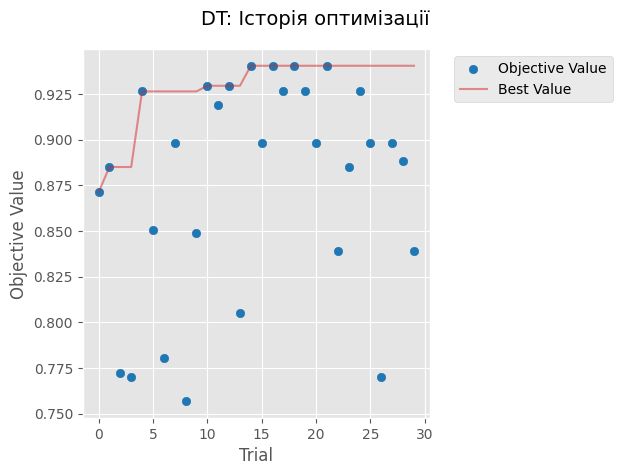

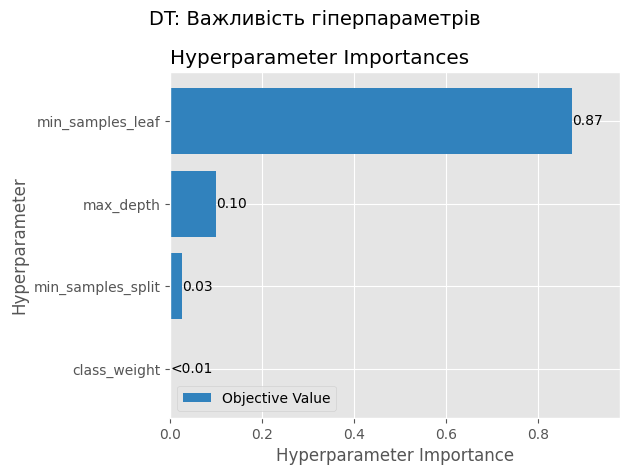

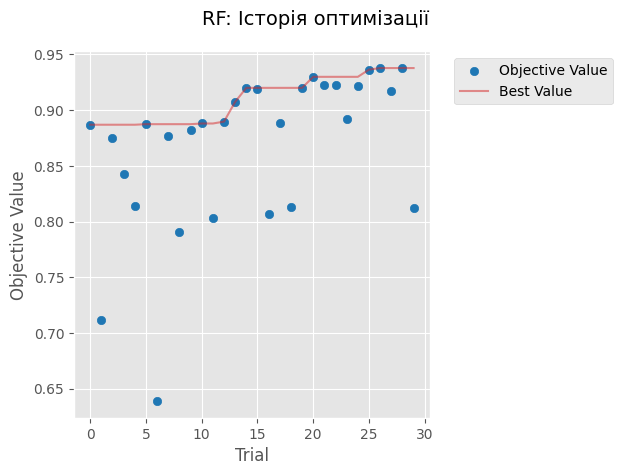

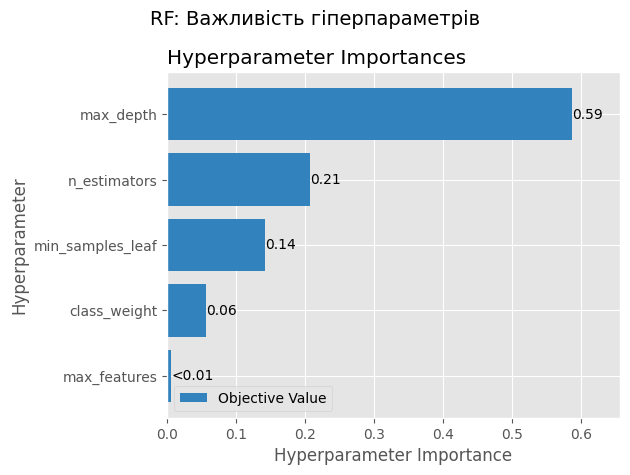

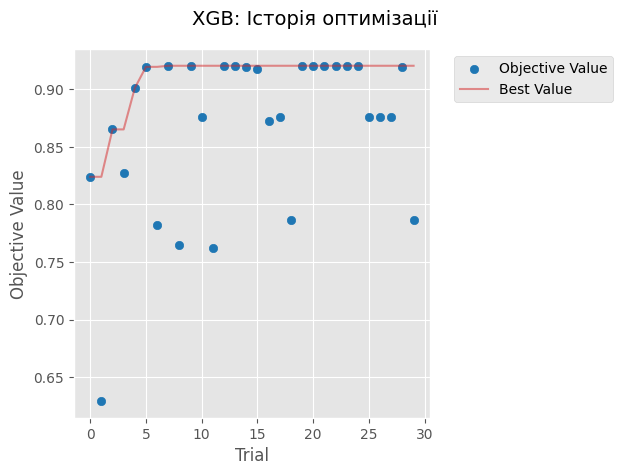

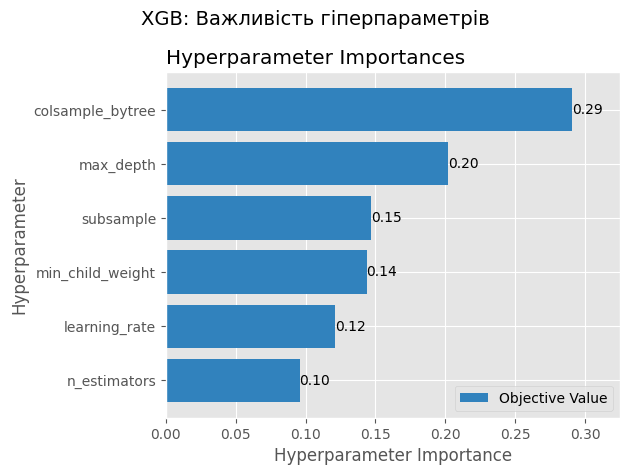

In [18]:
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances
import matplotlib.pyplot as plt

for name, model in final_models.items():
    # Відтворюємо study для графіків
    study = tune(name, X_train, y_train, n_trials=30)

    # 1. Графік історії оптимізації
    ax1 = plot_optimization_history(study)
    ax1.set_title("") # Очищаємо стандартний заголовок Optuna
    ax1.figure.suptitle(f'{name}: Історія оптимізації', fontsize=14)
    plt.tight_layout()
    plt.show()

    # 2. Графік важливості параметрів
    ax2 = plot_param_importances(study)
    ax2.set_title("") # Очищаємо стандартний заголовок Optuna
    ax2.figure.suptitle(f'{name}: Важливість гіперпараметрів', fontsize=14)
    plt.tight_layout()
    plt.show()

In [19]:
from scipy import stats

def nadeau_bengio_t_test(d, k=5, r=3):
    # Відношення розміру валідаційної до тренувальної вибірки (1/4 для 5-fold)
    n_test_n_train = 1 / (k - 1)

    d_mean = np.mean(d)
    d_var = np.var(d, ddof=1)

    # Знаменник тесту Наде-Бенжіо
    denominator = np.sqrt(d_var * (1 / (k * r) + n_test_n_train))

    if denominator == 0:
        return d_mean, 0.0, 1.0

    t_stat = d_mean / denominator
    df = k * r - 1
    p_val = stats.t.sf(np.abs(t_stat), df) * 2 # двосторонній тест

    return d_mean, t_stat, p_val

print("Збір метрик для статистичного порівняння...")
cv_scores = {'A': {}, 'B': {}}
for name in models:
    for var_name, with_ind in [('A', False), ('B', True)]:
        pipe = build_pipeline(name, with_ind)
        res = cross_validate(pipe, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
        cv_scores[var_name][name] = res['test_score']

comparison_results = []

# 1. Порівняння Варіант А vs Варіант В для кожної моделі
for name in models:
    d = cv_scores['B'][name] - cv_scores['A'][name]
    d_mean, t_stat, p_val = nadeau_bengio_t_test(d)
    comparison_results.append({
        'Порівняння': f"{name}: Вар В - Вар А",
        'Різниця (d_mean)': f"{d_mean:.4f}",
        't-статистика': f"{t_stat:.4f}",
        'p-value': f"{p_val:.4e}",
        'Висновок': "Значуща" if p_val < 0.05 else "Незначуща"
    })

# 2. Порівняння двох найкращих моделей у Варіанті В
mean_scores_B = {name: np.mean(cv_scores['B'][name]) for name in models}
top2 = sorted(mean_scores_B, key=mean_scores_B.get, reverse=True)[:2]
model1, model2 = top2[0], top2[1]

d = cv_scores['B'][model1] - cv_scores['B'][model2]
d_mean, t_stat, p_val = nadeau_bengio_t_test(d)
comparison_results.append({
    'Порівняння': f"Топ-2 (Вар В): {model1} - {model2}",
    'Різниця (d_mean)': f"{d_mean:.4f}",
    't-статистика': f"{t_stat:.4f}",
    'p-value': f"{p_val:.4e}",
    'Висновок': "Значуща" if p_val < 0.05 else "Незначуща"
})

df_stat = pd.DataFrame(comparison_results)
print("\nТаблиця 5: Результати статистичного порівняння")
display(df_stat)

Збір метрик для статистичного порівняння...

Таблиця 5: Результати статистичного порівняння


,Порівняння,Різниця (d_mean),t-статистика,p-value,Висновок
0,DT: Вар В - Вар А,0.1068,2.0860,5.5753e-02,Незначуща
1,RF: Вар В - Вар А,0.0558,4.0684,1.1511e-03,Значуща
2,XGB: Вар В - Вар А,0.0584,2.2670,3.9756e-02,Значуща
3,Топ-2 (Вар В): DT - RF,0.0060,0.3379,7.4046e-01,Незначуща



Таблиця 6: Якість фінальних моделей на тестовій вибірці


,Model,Accuracy,Macro F1,Balanced Acc
0,DT,0.9833,0.9149,0.8971
1,RF,0.9833,0.9838,0.9956
2,XGB,0.9944,0.9859,0.9750



Найкраща модель: XGB

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00        20
           3       0.99      1.00      1.00       137
           5       1.00      1.00      1.00        13
           U       1.00      0.88      0.93         8

    accuracy                           0.99       180
   macro avg       1.00      0.97      0.99       180
weighted avg       0.99      0.99      0.99       180



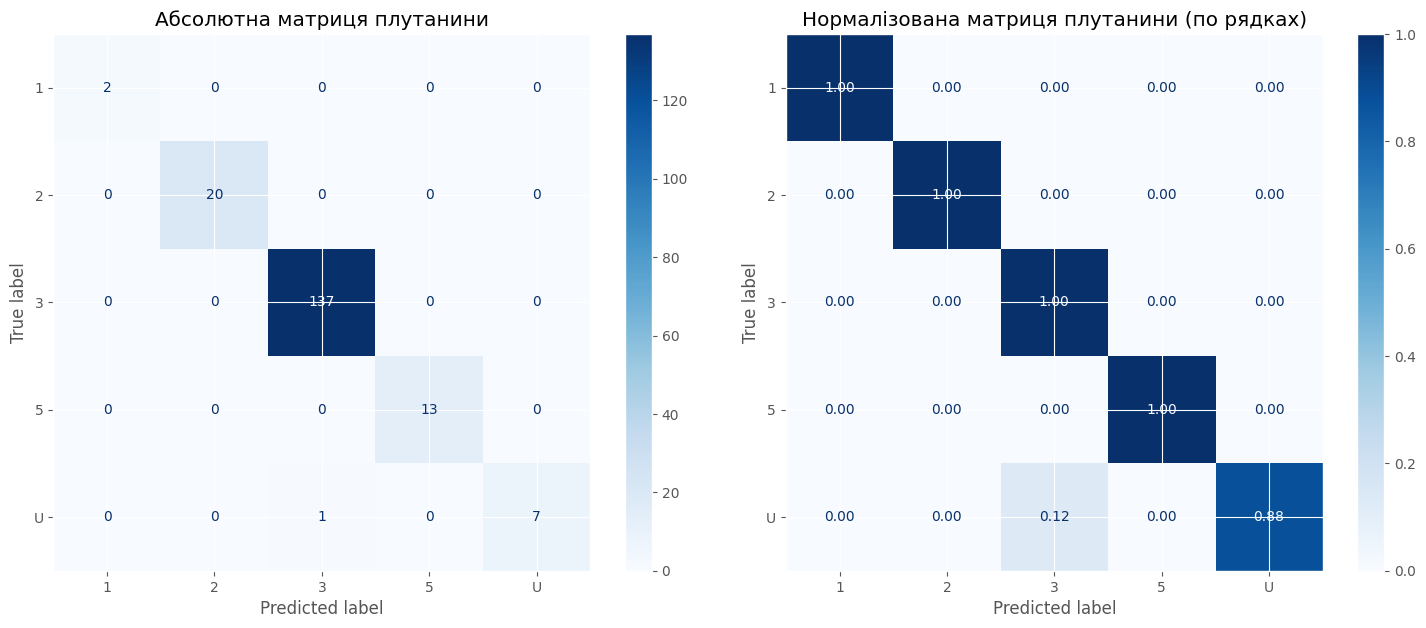

In [20]:
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

test_results = []
best_f1 = 0
best_model_name = None

for name, model in final_models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')
    bacc = balanced_accuracy_score(y_test, y_pred)

    test_results.append({
        'Model': name,
        'Accuracy': f"{acc:.4f}",
        'Macro F1': f"{f1:.4f}",
        'Balanced Acc': f"{bacc:.4f}"
    })

    if f1 > best_f1:
        best_f1 = f1
        best_model_name = name

df_test = pd.DataFrame(test_results)
print("\nТаблиця 6: Якість фінальних моделей на тестовій вибірці")
display(df_test)

print(f"\nНайкраща модель: {best_model_name}")
best_model = final_models[best_model_name]
y_pred_best = best_model.predict(X_test)
target_names = [str(c) for c in le.inverse_transform(np.unique(y_test))]

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best, target_names=target_names))

# Матриці плутанини
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

cm_abs = confusion_matrix(y_test, y_pred_best)
disp_abs = ConfusionMatrixDisplay(confusion_matrix=cm_abs, display_labels=target_names)
disp_abs.plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Абсолютна матриця плутанини')

cm_norm = confusion_matrix(y_test, y_pred_best, normalize='true')
disp_norm = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=target_names)
disp_norm.plot(ax=axes[1], cmap='Blues', values_format='.2f')
axes[1].set_title('Нормалізована матриця плутанини (по рядках)')

plt.tight_layout()
plt.show()

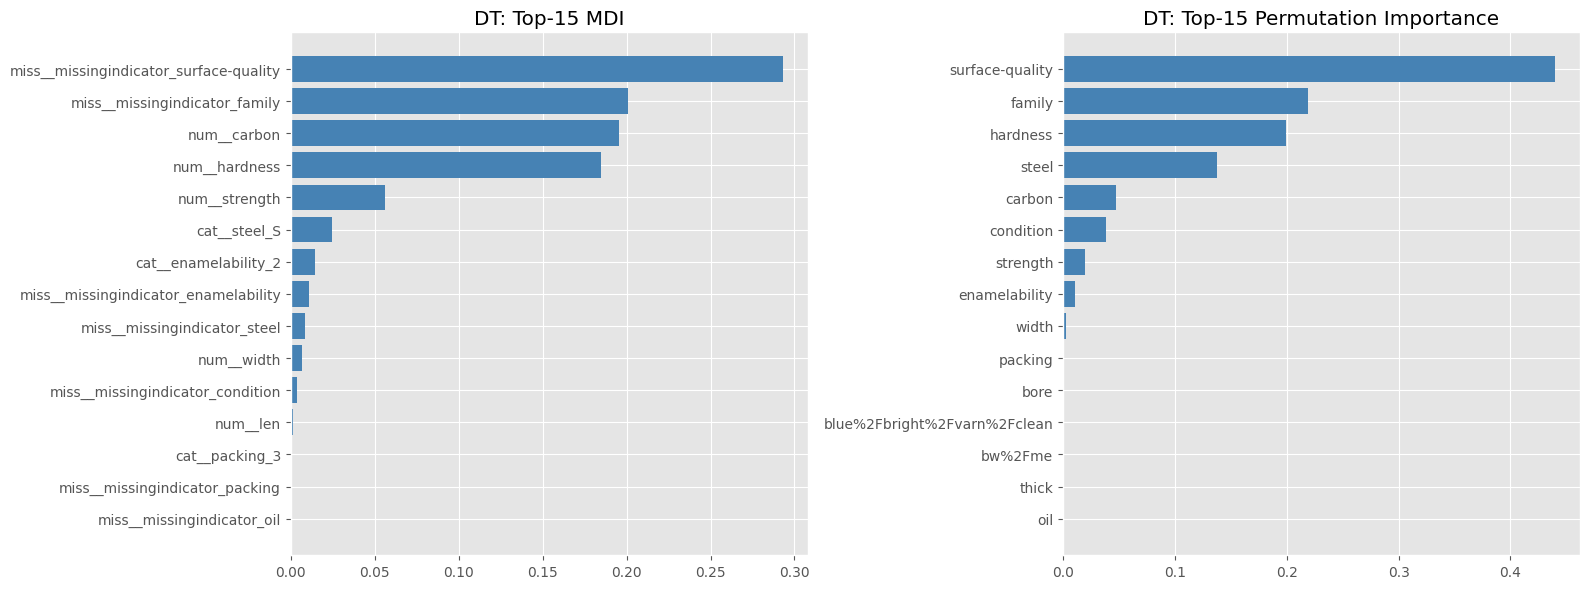

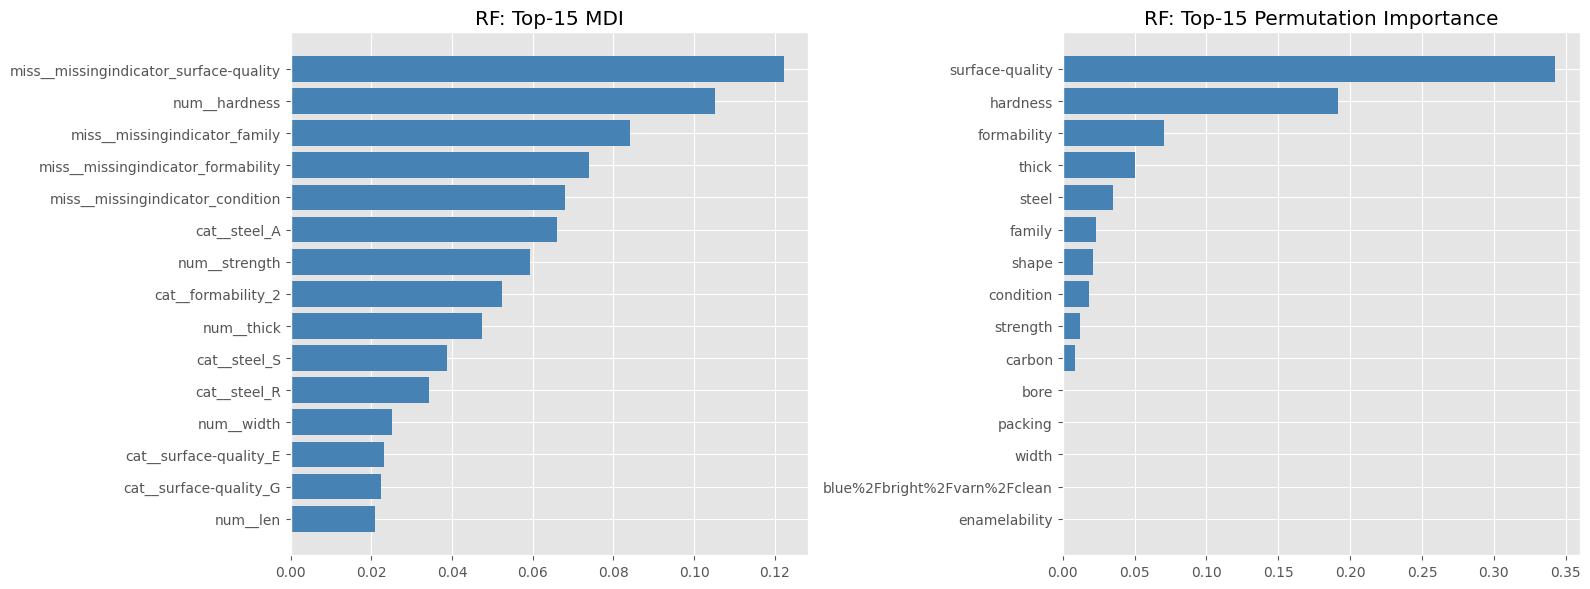

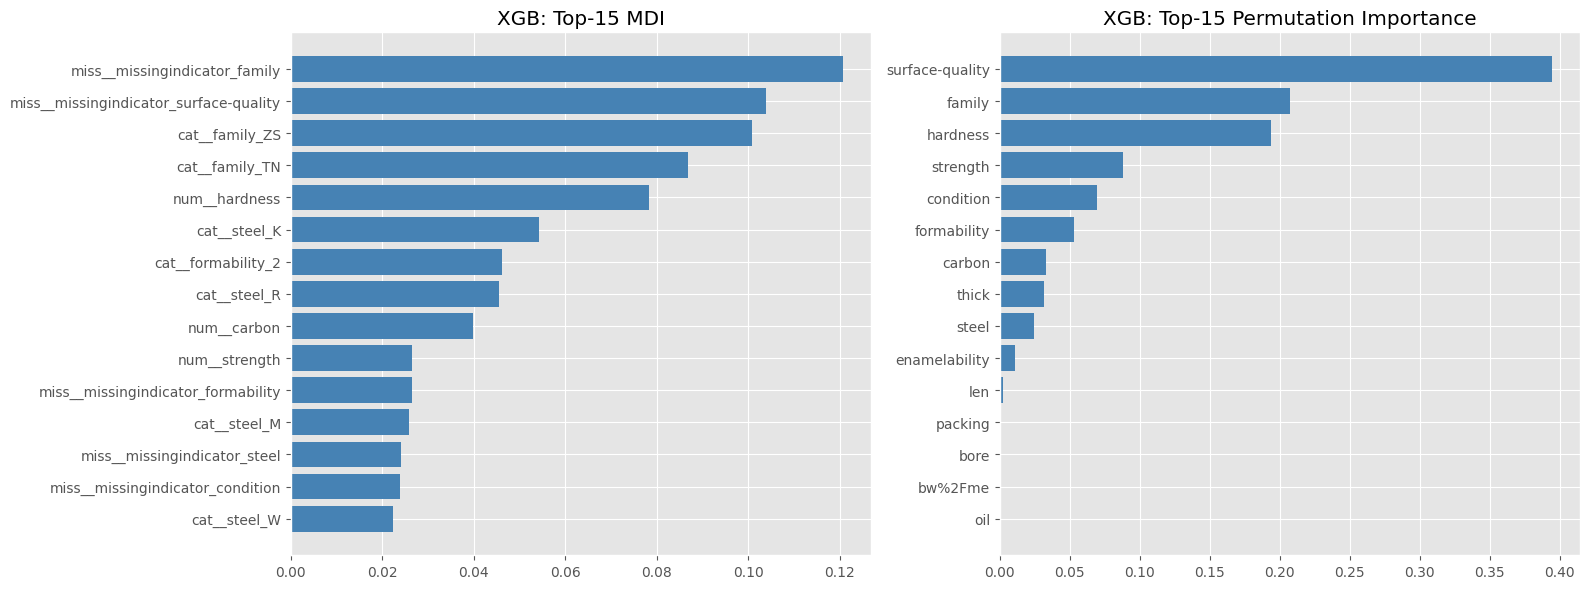

In [21]:
from sklearn.inspection import permutation_importance

def plot_top15_importance(importances, names, title, ax):
    indices = np.argsort(importances)[-15:]
    ax.barh(range(len(indices)), importances[indices], align='center', color='steelblue')
    ax.set_yticks(range(len(indices)))
    ax.set_yticklabels(np.array(names)[indices])
    ax.set_title(title)

for name, model in final_models.items():
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # 1. MDI Важливість (обчислюється на оброблених ознаках)
    clf = model.named_steps['clf']
    prep = model.named_steps['prep']
    feature_names_out = prep.get_feature_names_out()

    mdi_importances = clf.feature_importances_
    plot_top15_importance(mdi_importances, feature_names_out, f'{name}: Top-15 MDI', axes[0])

    # 2. Permutation Importance (на тестовій вибірці)
    result = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=SEED, scoring='f1_macro', n_jobs=-1)
    plot_top15_importance(result.importances_mean, X_test.columns, f'{name}: Top-15 Permutation Importance', axes[1])

    plt.tight_layout()
    plt.show()

In [23]:
import shap
from sklearn.model_selection import cross_val_predict

# 1. Знаходимо об'єкти розбіжностей (out-of-fold на X_train)
y_pred_oof = {}
for name, model in final_models.items():
    y_pred_oof[name] = cross_val_predict(model, X_train, y_train, cv=3, n_jobs=-1)

discrepancies = []
for i in range(len(X_train)):
    preds = {name: y_pred_oof[name][i] for name in models}
    if len(set(preds.values())) > 1:
        discrepancies.append(i)

print(f"Знайдено розбіжностей: {len(discrepancies)}")

# Формуємо таблицю розбіжностей (Таблиця 7)
disc_data = []
for idx in discrepancies[:3]:  # Беремо перші 3
    # ВИПРАВЛЕННЯ: y_train[idx] замість y_train.iloc[idx]
    row = {'Об\'єкт': idx, 'Справжній клас': le.inverse_transform([y_train[idx]])[0]}
    for name in models:
        row[name] = le.inverse_transform([y_pred_oof[name][idx]])[0]
    disc_data.append(row)

df_disc = pd.DataFrame(disc_data)
print("\nТаблиця 7: Об'єкти розбіжностей")
display(df_disc)

# 2. Детальний аналіз першого об'єкта розбіжності
if len(discrepancies) > 0:
    target_idx = discrepancies[0]
    print(f"\nДетальний аналіз для об'єкта #{target_idx}")

    # Виводимо початкові значення ознак (до імпутації)
    original_row = X_train.iloc[target_idx]
    print("\nОзнаки об'єкта (до імпутації):")
    for col, val in original_row.items():
        if pd.isna(val):
            print(f"{col}: Пропуск (буде імпутовано)")
        else:
            print(f"{col}: {val}")

    # 3. Аналіз SHAP
    xgb_model = final_models['XGB']
    prep = xgb_model.named_steps['prep']
    clf = xgb_model.named_steps['clf']

    X_target_processed = prep.transform(X_train.iloc[[target_idx]])
    feature_names = prep.get_feature_names_out()

    explainer = shap.TreeExplainer(clf)
    shap_values = explainer.shap_values(X_target_processed)

    predicted_class_enc = y_pred_oof['XGB'][target_idx]
    predicted_class_name = le.inverse_transform([predicted_class_enc])[0]
    print(f"\nПрогноз XGBoost: клас {predicted_class_name}")

    # ВИПРАВЛЕННЯ: універсальна обробка розмірності SHAP значень
    if isinstance(shap_values, list):
         shap_vals_class = shap_values[predicted_class_enc][0]
    elif len(shap_values.shape) == 3:
         # Формат (n_samples, n_features, n_classes)
         shap_vals_class = shap_values[0, :, predicted_class_enc]
    else:
         # Формат для бінарної/деяких інших версій (n_samples, n_features)
         shap_vals_class = shap_values[0]

    # Топ-5 ознак
    top_indices = np.argsort(np.abs(shap_vals_class))[-5:][::-1]

    print("\nТоп-5 ознак з найбільшим внеском (SHAP):")
    for idx in top_indices:
        feat_name = feature_names[idx]
        val = X_target_processed[0, idx]
        contrib = shap_vals_class[idx]
        print(f"Ознака: {feat_name} | Значення: {val:.4f} | SHAP внесок: {contrib:.4f}")

Знайдено розбіжностей: 10

Таблиця 7: Об'єкти розбіжностей


,Об'єкт,Справжній клас,DT,RF,XGB
0,6,3,2,3,3
1,25,1,1,1,3
2,54,3,2,3,3



Детальний аналіз для об'єкта #6

Ознаки об'єкта (до імпутації):
family: Пропуск (буде імпутовано)
steel: V
carbon: 0
hardness: 0
condition: S
formability: 2
strength: 0
surface-quality: Пропуск (буде імпутовано)
enamelability: 1
bw%2Fme: Пропуск (буде імпутовано)
blue%2Fbright%2Fvarn%2Fclean: Пропуск (буде імпутовано)
shape: COIL
thick: 0.699
width: 609.9
len: 0
oil: Пропуск (буде імпутовано)
bore: 0
packing: Пропуск (буде імпутовано)

Прогноз XGBoost: клас 3

Топ-5 ознак з найбільшим внеском (SHAP):
Ознака: miss__missingindicator_surface-quality | Значення: 1.0000 | SHAP внесок: -1.4397
Ознака: cat__steel_V | Значення: 1.0000 | SHAP внесок: 1.3621
Ознака: num__carbon | Значення: 0.0000 | SHAP внесок: -0.2973
Ознака: cat__enamelability_1 | Значення: 1.0000 | SHAP внесок: 0.2788
Ознака: num__thick | Значення: 0.6990 | SHAP внесок: 0.2099
